## Подготовка данных (Feature Engineering)

In [2]:
import pandas as pd

# Загружаем очищенные данные заново
df = pd.read_csv('../data/processed/cleaned_data.csv')

# 1. Разделяем признаки (X) и целевую переменную (y)
X = df.drop(columns=['Churn'])
y = df['Churn'].map({'No': 0, 'Yes': 1}) # Переводим Yes/No в 1/0

# 2. Кодируем категориальные признаки (One-Hot Encoding)
# Это создаст новые колонки-флаги (например, Contract_Month-to-month = 1 или 0)
X_encoded = pd.get_dummies(X, drop_first=True)

print("Размер данных до кодирования:", X.shape)
print("Размер данных после кодирования:", X_encoded.shape)

# 3. Разделяем данные на Обучающую (Train) и Тестовую (Test) выборки
from sklearn.model_selection import train_test_split

# stratify=y гарантирует, что пропорция ушедших (26%) сохранится и в трейне, и в тесте
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Размер Train: {X_train.shape[0]} строк")
print(f"Размер Test: {X_test.shape[0]} строк")

Размер данных до кодирования: (7043, 19)
Размер данных после кодирования: (7043, 30)
Размер Train: 5634 строк
Размер Test: 1409 строк


## Код для обучения модели (Baseline)

In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score

# Создаем модель (class_weight='balanced' важен из-за нашего дисбаланса 26/74)
model = LogisticRegression(class_weight='balanced', max_iter=1000)

# Обучаем
model.fit(X_train, y_train)

# Предсказываем
y_pred = model.predict(X_test)
y_pred_proba = model.predict_proba(X_test)[:, 1]

# Оценка
print("--- Отчет по классификации ---")
print(classification_report(y_test, y_pred))
print(f"ROC-AUC: {roc_auc_score(y_test, y_pred_proba):.4f}")

--- Отчет по классификации ---
              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1035
           1       0.50      0.79      0.62       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409

ROC-AUC: 0.8423


d:\01_Study\Case_02_Telco_Churn\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


## Масштабирование и улучшение

In [6]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Создаем Pipeline: сначала масштабируем данные, потом обучаем модель
# Это защищает от утечки данных и убирает предупреждение
model_scaled = make_pipeline(
    StandardScaler(), 
    LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42)
)

model_scaled.fit(X_train, y_train)

# Новые предсказания
y_pred_scaled = model_scaled.predict(X_test)
y_pred_proba_scaled = model_scaled.predict_proba(X_test)[:, 1]

print(f"Новый ROC-AUC: {roc_auc_score(y_test, y_pred_proba_scaled):.4f}")

Новый ROC-AUC: 0.8414


## SHAP-анализ (Поиск факторов риска)

Background dataset has 5634 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=5634 when initializing the masker.


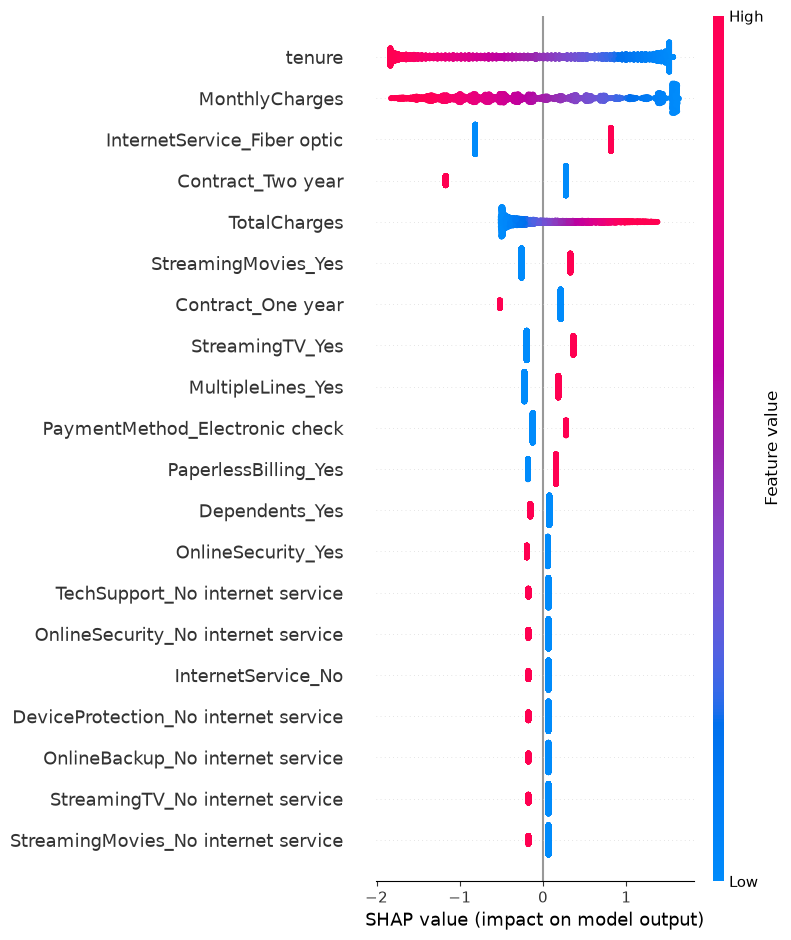

In [7]:
import shap
import matplotlib.pyplot as plt

# 1. Достаем обученные шаги из Pipeline
log_reg = model_scaled.named_steps['logisticregression']
scaler = model_scaled.named_steps['standardscaler']

# 2. Масштабируем тренировочные данные (SHAP требует те же данные, на которых учились)
X_train_scaled = scaler.transform(X_train)

# 3. Создаем объяснение
explainer = shap.LinearExplainer(log_reg, X_train_scaled)
shap_values = explainer.shap_values(X_train_scaled)

# 4. Строим красивый график (summary plot)
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X_train, feature_names=X_train.columns, show=False)
plt.tight_layout()
plt.show()